#### Data Preparation & Visualization
To test the classifier's mechanics, we build a synthetic dataset using `sklearn`. Setting `n_features=2` and `n_redundant=0` ensures the data is perfectly tailored for spatial visualization without unnecessary noise. Plotting the raw feature matrix gives us an immediate understanding of the class distribution and the complexity of the separation task ahead.
.

Shape of X: (1000, 2)
Shape of y: (1000,)


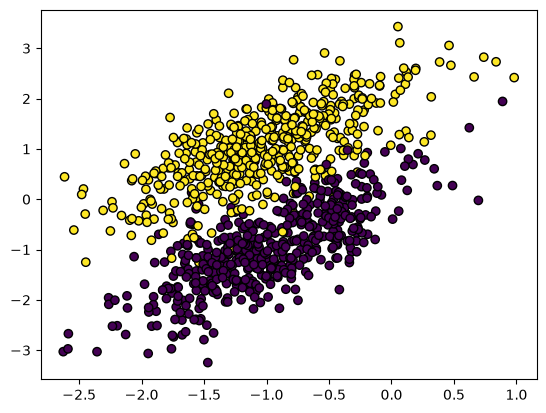

In [1]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt

X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=12)

print(f'Shape of X: {X.shape}\nShape of y: {y.shape}')

plt.scatter (X[:, 0], X[:, 1], c=y, edgecolor='k')
plt.show()

X train: (800, 2)
y train: (800,)
X test: (200, 2)
y test: (200,)


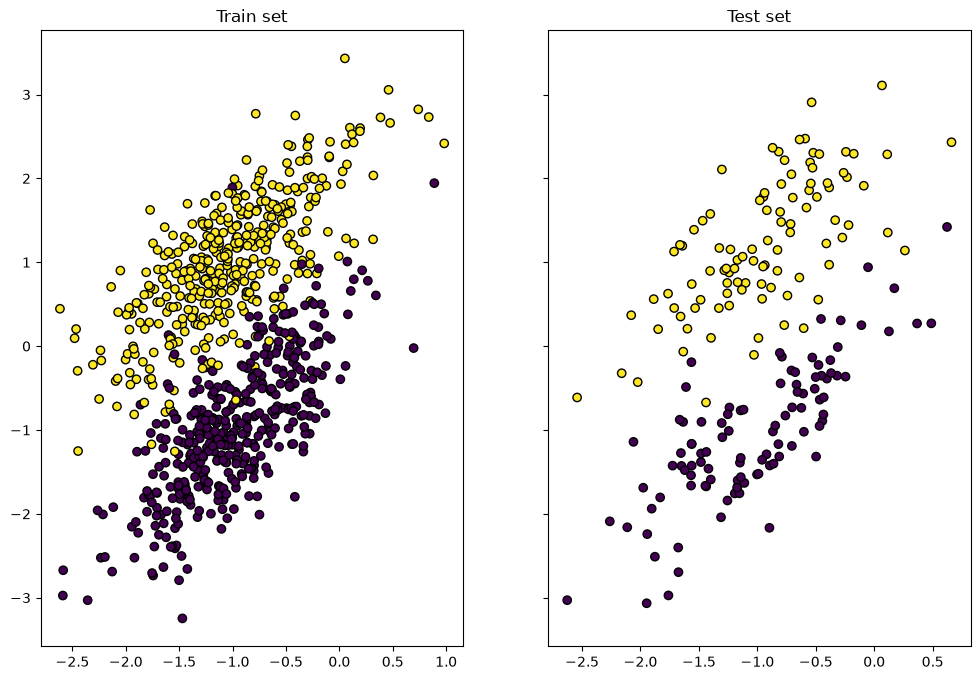

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=12)

print(f'X train: {X_train.shape}\ny train: {y_train.shape}\nX test: {X_test.shape}\ny test: {y_test.shape}')

fig, axes = plt.subplots(1, 2, figsize=(12,8), sharey=True)
axes[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor='k')
axes[0].set_title('Train set')
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor='k')
axes[1].set_title('Test set')
plt.show()

## Random Forest Classifier: Implementation from Scratch

This section extends our fundamental implementation of the CART Decision Tree into a robust ensemble algorithm — the **Random Forest**. While the core logic of calculating impurity (Gini/Entropy) and recursive node splitting remains identical to the previous notebook, two critical levels of stochasticity (randomness) have been introduced to ensure the individual trees are uncorrelated.

### 1. Feature Subsampling (Modifications to `MyDecisionTree`)
To prevent highly predictive features from dominating the root splits of every single tree, we introduce the **Random Subspace Method**. 


**`max_features` parameter:** During the `build_tree` process, the algorithm no longer evaluates all available features to find the optimal split. Instead, it randomly selects a subset of features (without replacement).


### 2. The `MyRandomForest` Ensemble Class
The forest acts as an orchestrator for multiple decision trees, relying on the statistical principles of **Bootstrap Aggregating (Bagging)** and **Majority Voting**.

* **Bootstrap Sampling (`fit` method):** For every tree defined by `n_estimators`, the algorithm generates a new training dataset of the same size by sampling the original data *with replacement* (`replace=True`). Consequently, each tree learns from a slightly distorted distribution, allowing it to specialize in different subsets of the feature space.
* **Majority Vote (`predict` method):** During inference, the input matrix is passed through every fitted tree in the ensemble. The final predicted class is determined by taking the mode (the most frequent prediction) across all trees using `scipy.stats.mode`. 

By combining bootstrap sampling (which disrupts the data) and feature subsampling (which disrupts the splits), this architecture drastically reduces model variance and mitigates the overfitting typically associated with deep, standalone decision trees.

In [3]:
import numpy as np

class Node:
    def __init__(self, right_child=None, left_child=None, t=0, idx_feature=0, output_class=None, prob=None, probas=None):
        self.threshold = t
        self.idx_feature = idx_feature
        self.right_child = right_child
        self.left_child = left_child
        self.output_class = output_class
        self.prob_class_1 = prob
        self.probas = probas
        


class MyDecisionTree:
    def __init__(self, max_features, max_depth=10, min_samples_per_leaf=15):
        self.max_depth = max_depth
        self.min_samples_per_leaf = min_samples_per_leaf
        self.root = None
        self.max_features = max_features

    
    def impurity(self, y, I='Gini'):

        unique_values_counts = np.unique(y, return_counts=True)
        probs = unique_values_counts[1] / len(y)        
        
        if I == 'Gini':
            res = 1 - np.sum(probs ** 2)
        elif I == 'Entropy':
            res = - np.sum(probs * np.log2(probs))
            
        return res
        

    def information_gain(self, y, y_left, y_right, I='Gini'):

        ig = self.impurity(y, I=I) - (len(y_left)/len(y) * self.impurity(y_left, I=I) + len(y_right)/len(y) * self.impurity(y_right, I=I))

        return ig
        

    def build_tree(self, X, y, depth=0):
        n_features = X.shape[1]
        max_ig = 0
        best_t = 0

        if (depth >= self.max_depth) or (len(np.unique(y)) == 1) or (len(y) < self.min_samples_per_leaf):
            unique_vals, unique_cnts = np.unique(y, return_counts=True)
            output_class = unique_vals[np.argmax(unique_cnts)]

            prob = np.sum(y == 1) / len(y)
            probas = dict()

            return Node(output_class=output_class, prob=prob, probas=probas)
        
        actual_max_features = min(self.max_features, n_features)
        random_features = np.random.choice(n_features, size=actual_max_features, replace=False)
        for i in random_features:
            thresholds = np.unique(X[:,i])
            max_ig_feature = 0
            max_threshold = 0
                
            for t in thresholds:
                mask = X[:, i] < t
                y_left = y[mask]
                y_right = y[~mask]
                ig = self.information_gain(y, y_left, y_right)
                if ig > max_ig_feature:
                    max_ig_feature = ig
                    max_threshold = t
    
            if max_ig_feature > max_ig:
                max_ig = max_ig_feature
                max_feature = i
                best_t = max_threshold

        best_mask = X[:, max_feature] < best_t

        X_left = X[best_mask]
        y_left = y[best_mask]
        X_right = X[~best_mask]
        y_right = y[~best_mask]

        left_child = self.build_tree(X_left, y_left, depth=depth+1)
        right_child = self.build_tree(X_right, y_right, depth=depth+1)

        return Node(right_child=right_child, left_child=left_child, idx_feature=max_feature, t=best_t)
            

    def fit(self, X, y):
        self.root = self.build_tree(X, y)


    def traverse_tree(self, x, node):
        if node.output_class is not None:
            return node.output_class

        if x[node.idx_feature] < node.threshold:
            return self.traverse_tree(x, node.left_child)
        else:
            return self.traverse_tree(x, node.right_child)
        
    

    def predict(self, X):
        y_preds = np.zeros(len(X))

        for i in range(len(X)):
            y_preds[i] = self.traverse_tree(X[i], self.root)

        return y_preds


    def traverse_tree_proba(self, x, node):
        if node.prob_class_1 is not None:
            return node.prob_class_1

        if x[node.idx_feature] < node.threshold:
            return self.traverse_tree_proba(x, node.left_child)
        else:
            return self.traverse_tree_proba(x, node.right_child)


    def predict_proba(self, X):
        y_probas = np.zeros(len(X))

        for i in range(len(X)):
            y_probas[i] = self.traverse_tree_proba(X[i], self.root)


        return y_probas
        
        

    def accuracy(self, X, y):
        y_preds = self.predict(X)
        acc = np.sum(y_preds == y) / len(y)
        return acc
    

In [4]:
from scipy import stats

class MyRandomForest:
    def __init__(self, n_estimators=10, max_features=10):
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.trees = []

    def fit(self, X, y):
        self.models_fitted = []
        for i in range(self.n_estimators):
            model = MyDecisionTree(self.max_features)
            indices = np.random.choice(len(X), len(X), replace=True)
            X_bootstrapped = X[indices]
            y_bootstrapped = y[indices]
            model.fit(X_bootstrapped, y_bootstrapped)
            self.models_fitted.append(model)

    def predict(self, X):
        y_preds = np.zeros((len(self.models_fitted), len(X)))
        i = 0                           
        for model in self.models_fitted:
            y_pred = model.predict(X)
            y_preds[i] = y_pred
            i += 1
        preds = stats.mode(y_preds, axis=0)

        return preds.mode
        


    

## Model Evaluation and Spatial Analysis

Having implemented the Random Forest ensemble from scratch, the next critical step is to evaluate its generalization capability and visually inspect its behavior in the feature space. 

### 1. Quantitative Metrics and Confusion Matrix
To rigorously assess the performance of our custom model, we compute standard classification metrics using `scikit-learn`. 
* **Classification Report & Accuracy:** The ensemble demonstrates robust predictive capacity on unseen data, achieving an outstanding overall accuracy of 95%. 
* **Confusion Matrix:** Visualizing the predictions via a Seaborn heatmap provides a granular breakdown of the model's errors. The matrix reveals highly symmetric performance, with the model making only a negligible number of misclassifications (4 false positives and 5 false negatives). This indicates that the ensemble is not biased toward a specific majority class.


In [5]:
my_random_forest = MyRandomForest()
my_random_forest.fit(X_train, y_train)
preds = my_random_forest.predict(X_test)

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

print(accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

0.955
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       102
           1       0.95      0.96      0.95        98

    accuracy                           0.95       200
   macro avg       0.95      0.96      0.95       200
weighted avg       0.96      0.95      0.96       200



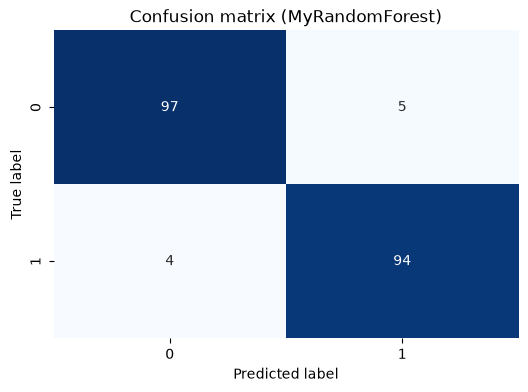

In [7]:
cm = confusion_matrix(y_test, preds)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion matrix (MyRandomForest)')
plt.show()

### 2. Decision Boundary Visualization (Meshgrid Technique)
Evaluating quantitative metrics is essential, but visualizing the decision boundary provides deeper geometric intuition about how the algorithm partitions the data. 

To achieve this, we construct a dense 2D coordinate grid (`np.meshgrid`) spanning the minimum and maximum limits of our feature space. We then pass every synthetic point in this grid through our `predict` method, mapping the continuous spatial regions assigned to each class.
* **Training Set Topology:** The resulting contour plot for the training set shows how the algorithm successfully separates the blue and red clusters. While a single Decision Tree tends to draw rigid, overfitted rectangular boxes around localized noise, the Random Forest aggregates multiple randomized trees, yielding a much smoother and more generalized step-wise boundary.
* **Test Set Generalization:** Projecting the unseen test data onto this exact same decision surface confirms the ensemble's robustness. The boundary effectively separates the test clusters without capturing the structural noise of the training set, validating the variance-reduction benefits of bootstrap aggregating (bagging).

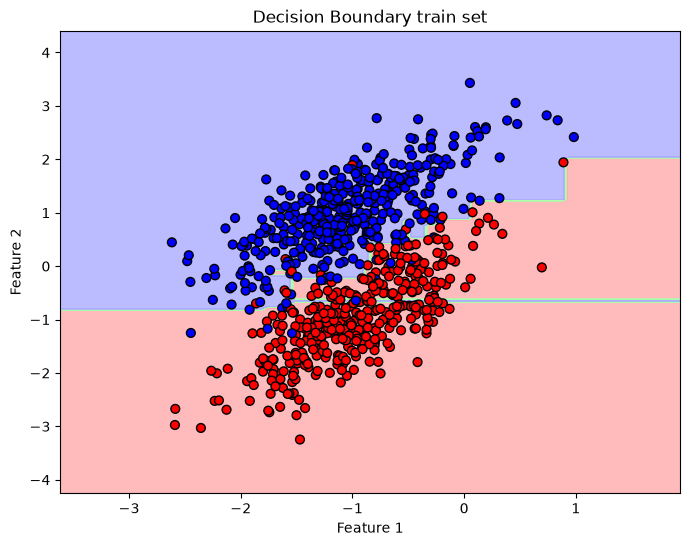

In [8]:
from matplotlib.colors import ListedColormap

x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = my_random_forest.predict(grid_points)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])  

plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)

plt.title("Decision Boundary train set")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

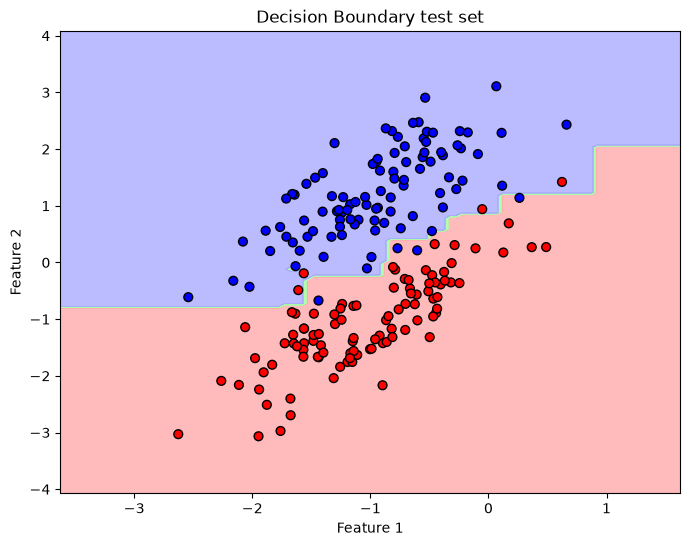

In [9]:
from matplotlib.colors import ListedColormap

x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = my_random_forest.predict(grid_points)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])  

plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cmap_bold, edgecolor='k', s=40)

plt.title("Decision Boundary test set")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## Conclusion

In this experiment, we extended our custom Decision Tree implementation into an ensemble **Random Forest** classifier using pure NumPy. By integrating two layers of stochasticity — **bootstrap aggregating (bagging)** across observations and **random subspace feature selection** across split candidates — the ensemble fundamentally addresses the high variance and overfitting characteristic of standalone CART trees. 

The empirical results confirm the theoretical advantages:
* **High Predictive Precision:** The model attained a 95% overall test accuracy with balanced false positive and false negative rates, demonstrating strong generalization without majority-class bias.
* **Geometric Regularization:** Spatial visualization of the decision boundary highlights the smoothing effect of majority voting, producing resilient piecewise-linear partitions rather than brittle, over-specialized thresholds.

Overall, this custom implementation validates the power of ensemble variance reduction, bridging foundational tree theory with production-grade ensembling principles.